 1. Hallar la solución del problema de valor inicial

$$
\begin{cases}
y' = y - 1 \\
y(0) = 2
\end{cases}
$$

en el intervalo $[0,7]$.

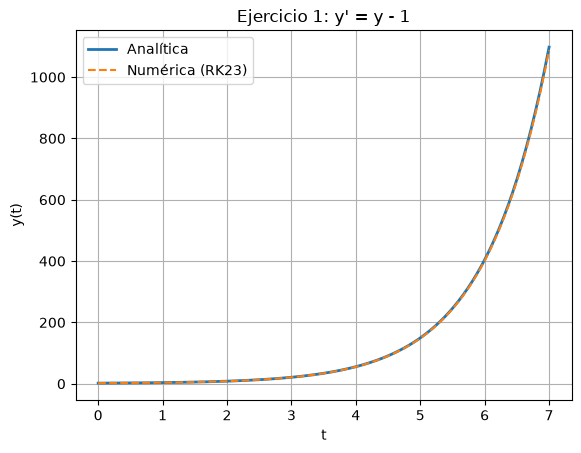

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# --- Ejercicio 1: y' = y - 1, y(0) = 2, en [0,7] ---

# Opción A: solución analítica 
y0 = 2
a = 1
b = -1 
C = y0 + (b/a)
tmax = 7
tt_analitico = np.linspace(0, tmax, 200)
yy_analitico = (-b/a) + C*np.exp(a*tt_analitico)

# Opción B: solución numérica con solve_ivp
def f(t, y):
    return y - 1   # la ecuación diferencial, no la solución

sol = solve_ivp(f, [0, tmax], [2], method='RK23', t_eval=np.linspace(0, tmax, 200))

# Graficar ambas
plt.plot(tt_analitico, yy_analitico, label='Analítica', linewidth=2)
plt.plot(sol.t, sol.y[0], '--', label='Numérica (RK23)')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.title("Ejercicio 1: y' = y - 1")
plt.legend()
plt.grid(True)
plt.show()


2. En ciertas circunstancias, el número de individuos en determinadas poblaciones de bacterias se rige por la ley

$$
y' = 0.2y
$$

Si al comienzo del experimento hay 30.000 bacterias:

**(a)** ¿Cuántas habrá 10 horas más tarde?

**(b)** ¿En qué instante habrá 100.000 bacterias?

Valor analítico en t=10: 221671.6829679195
Valor numérico en t=10: 221209.27426589848


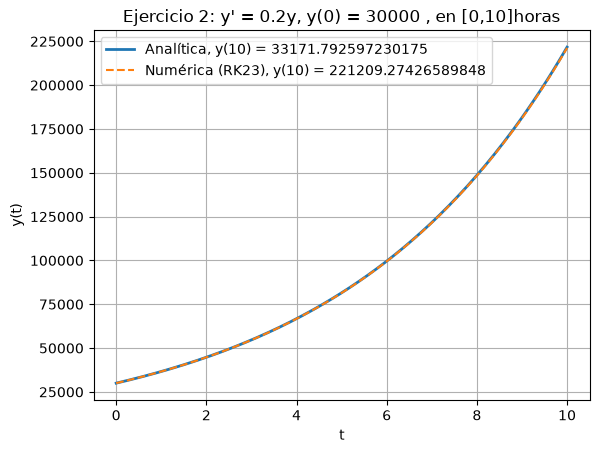

In [6]:
# %%# --- Ejercicio 2: y' = 0.2y, y(0) = 30000 , en [0,10]horas ---

# Opción A: solución analítica 
y0 = 30000
a = 0.2
b = 0 
C = y0 + (b/a)
tmax = 10
tt_analitico = np.linspace(0, tmax, 200)
yy_analitico = (-b/a) + C*np.exp(a*tt_analitico)

# Opción B: solución numérica con solve_ivp
dydt = lambda t, y: 0.2 * y  # la ecuación diferencial, no la solución

sol = solve_ivp(dydt, [0, tmax], [y0], method='RK23', t_eval=np.linspace(0, tmax, 200))
# solve_ivp es un struct que contiene la solución numérica, entre otros datos. 
# La solución numérica está en sol.y[0] y los tiempos en sol.t

"""Es decir, sol.y es una matriz:

La primera fila corresponde a la variable 
𝑦
Cada columna corresponde a un instante de tiempo."""

print (f"Valor analítico en t=10: {yy_analitico[-1]}")
print (f"Valor numérico en t=10: {sol.y[0][-1]}")

# Graficar ambas
plt.plot(tt_analitico, yy_analitico, label= f"Analítica, y(10) = {yy_analitico[tmax]}", linewidth=2)
plt.plot(sol.t, sol.y[0], '--', label= f"Numérica (RK23), y(10) = {sol.y[0][-1]}")
plt.xlabel('t')
plt.ylabel('y(t)')
plt.title("Ejercicio 2: y' = 0.2y, y(0) = 30000 , en [0,10]horas")
plt.legend()
plt.grid(True)
plt.show()


3. Se supone que la población de un país era de 39,5 millones en el año 2000 y que crece siguiendo la ley de Malthus
$$
y' = 0.05y
$$

donde $y(t)$ representa el número de millones de habitantes en el instante $t$.

**(a)** ¿Cuántos millones de habitantes habrá en 2010?

**(b)** ¿Cuándo se alcanzarán los 50 millones de habitantes?

In [13]:
# %%# --- Ejercicio 3: y' = 0.05y, y(0) = 39.5e6 , en [0,10]años ---

# Opción A: solución analítica 
y0 = 39.5 #cada unidad es 1e6
a = 0.05
b = 0 
C = y0 + (b/a)
tmax = 10 
staps = 365*10
tt_analitico = np.linspace(0, tmax, staps)
yy_analitico = (-b/a) + C*np.exp(a*tt_analitico)

#busco millones de habitantes en 2010, es decir, y(10) 
y_analitico_2010 = yy_analitico[-1]
print(f"Valor analítico en t=10: {y_analitico_2010} millones de habitantes")

#busco yy_analitico(t) = 50 => despejo tt_analitico
y_buscado = 50
tt_analitico50 = np.log((y_buscado + (b/a))/C)/a
print(f"Se alcanza la población de {y_buscado} millones en t={tt_analitico50} años")

# Opción B: solución numérica con solve_ivp
dydt = lambda t, y: 0.05 * y  # la ecuación diferencial, no la solución

sol = solve_ivp(dydt, [0, tmax], [y0], method='RK23', t_eval=tt_analitico)
# solve_ivp es un struct que contiene la solución numérica, entre otros datos. 
# La solución numérica está en sol.y[0] y los tiempos en sol.t

y_numerica_2010 = sol.y[0][-1]
print(f"Valor numérico en t=10: {y_numerica_2010} millones de habitantes")

t_numerica50 = np.log((y_buscado + (b/a))/C)/a
print(f"Se alcanza la población de {y_buscado} millones en t={t_numerica50} años")

Valor analítico en t=10: 65.12449019265506 millones de habitantes
Se alcanza la población de 50 millones en t=4.714446670421399 años
Valor numérico en t=10: 65.10653688488026 millones de habitantes
Se alcanza la población de 50 millones en t=4.714446670421399 años


4. Un objeto se coloca en una habitación que está a temperatura constante de $25^\circ C$. Se sabe que la constante de enfriamiento del objeto es $0.02$. Al comienzo la temperatura del objeto es de $55^\circ C$. Considerando la ley de enfriamiento de Newton dada por

$$
y' = k(t_a-y)
$$

donde $y$ denota la temperatura del objeto, $k$ su constante de enfriamiento y $t_a$ la temperatura ambiente:

**(a)** ¿Qué temperatura tendrá el objeto después de 50 minutos?

**(b)** ¿Cuánto tarda en ponerse a temperatura de $46^\circ C$?

**(c)** ¿Qué pasa con la temperatura después de varias horas?

In [18]:
# Opción A: solución analítica 
y0 = 55 #°C 
a = -0.02
b = 0.02*25
C = y0 + (b/a)
tmax = 10 #horas
staps = 60*10 #número de pasos, en este caso 60 pasos por hora, durante 10 horas
tt_analitico = np.linspace(0, tmax, staps)
yy_analitico = (-b/a) + C*np.exp(a*tt_analitico)

#busco millones de habitantes en 2010, es decir, y(10) 
y_analitico_50min = yy_analitico[50] #como tiempos tiene 60 pasos por hora, el paso 50 corresponde a 50 minutos
print("Resultados analíticos:")
print(f"A los 50 minutos : {y_analitico_50min} °C")

#busco yy_analitico(t) = 46 => despejo tt_analitico
y_buscado = 46
tt_analitico46 = np.log((y_buscado + (b/a))/C)/a
print(f"Se alcanza la temperatura {y_buscado} °C en t={tt_analitico46} minutos")
print("\n")

# Opción B: solución numérica con solve_ivp
dydt = lambda t, y: 0.05 * y + 0.02*25  # la ecuación diferencial, no la solución

sol = solve_ivp(dydt, [0, tmax], [y0], method='RK23', t_eval=tt_analitico)
# solve_ivp es un struct que contiene la solución numérica, entre otros datos. 
# La solución numérica está en sol.y[0] y los tiempos en sol.t

print("Resultados numéricos:")
y_numerica_50min = sol.y[0][50]
print(f"A los 50 minutos : {y_numerica_50min} °C")

t_numerica46 = np.log((y_buscado + (b/a))/C)/a
print(f"Se alcanza la temperatura {y_buscado} °C en t={t_numerica46} minutos")

Resultados analíticos:
A los 50 minutos : 54.50332269831145 °C
Se alcanza la temperatura 46 °C en t=17.83374719693662 minutos


Resultados numéricos:
A los 50 minutos : 57.77015626430244 °C
Se alcanza la temperatura 46 °C en t=17.83374719693662 minutos


6. Escribir un código que permita resolver numéricamente una ecuación diferencial ordinaria utilizando una función ODE.

        Utilizar el código para simular los sistemas de los ejercicios 7, 8 y 9 en un intervalo de tiempo conveniente y graficar la solución.

## Ya lo habia hecho para los otros pensando que era en todos

7. En algunos modelos de pesca se utiliza la ecuación

$$
y' = \alpha y \ln\left(\frac{k}{y}\right)-qy
$$

donde el término $-qy$ mide el efecto negativo que ejerce la pesca sobre el crecimiento de la población.

Estos modelos ayudan a analizar la sostenibilidad de los bancos de pesca.

Calcular y dibujar en un mismo gráfico las soluciones del problema para

$$
\alpha = 0.2,
\qquad
k = 27,
\qquad
y(0)=10
$$

variando los valores del parámetro $q$:

$$
q = 0,\ 0.05,\ 0.1,\ 0.2,\ 0.3.
$$

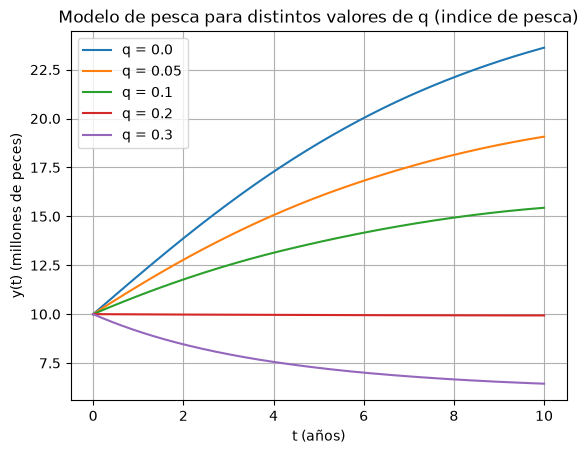

In [25]:
# Solución numérica del ejercicio 7
alfa = 0.2
k = 27
y0 = 10
tmax = 10
staps = 60 * 10
tt = np.linspace(0, tmax, staps)
qq = np.array([0, 0.05, 0.1, 0.2, 0.3])

# Una fila por cada valor de q y una columna por cada instante de tiempo
soluciones = np.zeros((len(qq), len(tt)))

for i in range(len(qq)):
    def f(t, y):
        return alfa * y * np.log(k / y) - qq[i] * y

    sol = solve_ivp(f, [0, tmax], [y0], method='RK23', t_eval=tt)
    soluciones[i, :] = sol.y[0]

# Todas las curvas se dibujan sobre los mismos ejes
for i in range(len(qq)):
    plt.plot(tt, soluciones[i, :], label=f'q = {qq[i]}')

plt.xlabel('t (años)')
plt.ylabel('y(t) (millones de peces)')
plt.title("Modelo de pesca para distintos valores de q (indice de pesca)")
plt.legend()
plt.grid(True)
plt.show()

8. Considere el siguiente sistema


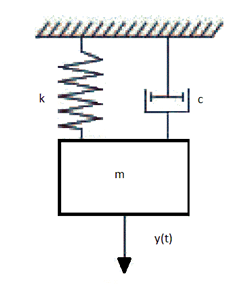

**(a)** Escriba la ecuación diferencial que describe el sistema.

**(b)** Resuelva la ecuación para

$$
m=5\,Kg,
\qquad
c=1000\,Ns/m,
\qquad
k=750\,N/m
$$

con una condición inicial

$$
y(0)=1\,m
$$

y velocidad inicial

$$
y'(0)=0.5\,m/s.
$$

**(c)** Escriba la representación en espacio de estado.

**(d)** Escriba el polinomio característico del modelo y la solución general.

**(e)** Resuelva en Matlab para los valores dados. Cambie de a uno los valores de los parámetros y observe los diferentes resultados.

1. ¿Qué ecuación diferencial tenemos?
Para un sistema masa-resorte-amortiguador:
$$
\
m y'' + c y' + ky = 0
\
$$

Reemplazamos nuestros valores:
$$
\
5y'' + 1000y' + 750y = 0
\
$$ 
Esta es una ecuación diferencial de segundo orden.
Como solve?ivp solo sabe trabajar sistemas de primer orden tengo que transformar a varios sistemas de primer orden.
Definimos una nueva variable:
$$
\
x_1 = y
\
$$
y
$$
\
x_2 = y'
\
$$
Entonces:
$$
\
x_1'=y'=x_2
\
$$
Ahora despejamos $ \ y'' \ $ de nuestra ecuación:
$$
\
5y''+1000y'+750y=0
\
$$
$$
\
y''=-\frac{1000}{5}y'-\frac{750}{5}y

y''=-200y'-150y
\
$$
Como $ \ x_1=y \ $   y    $ \ x_2=y' \ $ :
$$
\
x_2'=-150x_1-200x_2
\
$$
Por lo tanto, nuestro sistema queda:
$$
\
\boxed{
\begin{cases}
x_1'=x_2\\
x_2'=-150x_1-200x_2
\end{cases}}
\
$$
con condiciones iniciales:
$$
\
x_1(0)=1
\\
x_2(0)=0.5
\
$$

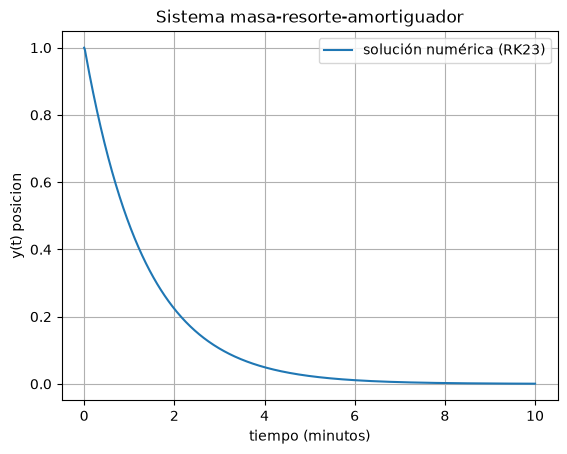

In [28]:
# Solución numérica del ejercicio 8

m = 5       # kg
c = 1000    # N s/m
k = 750     # N/m

# Condiciones iniciales
y0 = 1      # m
dydt0 = 0.5 # m/s
x0 = [y0, dydt0]

tmax = 10
staps = 60 * 10

tt = np.linspace(0, tmax, staps)

# Sistema de ecuaciones de primer orden
def f(t, x):

    x1 = x[0]   # x1 = y
    x2 = x[1]   # x2 = y'

    dx1dt = x2
    dx2dt = -(c/m)*x2 - (k/m)*x1

    return [dx1dt, dx2dt]


# Condiciones iniciales
x0 = [y0, dydt0]

# Resolver
sol = solve_ivp(f,[0, tmax],x0, method='RK23', t_eval=tt)

# Todas las curvas se dibujan sobre los mismos ejes
plt.plot(tt, sol.y[0], label= "solución numérica (RK23)")
plt.xlabel('tiempo (minutos)')
plt.ylabel('y(t) posicion')
plt.title("Sistema masa-resorte-amortiguador")
plt.legend()
plt.grid(True)
plt.show()

## Pasaje a espacio de estados 

La ecuación diferencial del sistema masa-resorte-amortiguador es:

$$
m y'' + c y' + ky = 0
$$

Definimos dos nuevas variables de estado:

$$
x_1 = y
$$

$$
x_2 = y'
$$

Entonces:

$$
x_1' = y' = x_2
$$

Despejando $y''$ de la ecuación diferencial:

$$
y'' = -\frac{c}{m}y' - \frac{k}{m}y
$$

Como $x_1=y$ y $x_2=y'$, obtenemos:

$$
x_2' = -\frac{c}{m}x_1-\frac{k}{m}x_2
$$

Para los valores del ejercicio:

$$
m=5,\qquad c=1000,\qquad k=750
$$

Por lo tanto:

$$
x_1'=x_2
$$

$$
x_2'=-150x_1-200x_2
$$

El sistema puede escribirse en forma matricial como:

$$
\boxed{
\begin{bmatrix}
x_1'\\
x_2'
\end{bmatrix}
=
\begin{bmatrix}
0 & 1\\
-150 & -200
\end{bmatrix}
\begin{bmatrix}
x_1\\
x_2
\end{bmatrix}
}
$$

Es decir:

$$
\boxed{\dot{x}=Ax}
$$

donde:

$$
A=
\begin{bmatrix}
0 & 1\\
-150 & -200
\end{bmatrix}
$$

Las condiciones iniciales son:

$$
x_1(0)=y(0)=1
$$

$$
x_2(0)=y'(0)=0.5
$$

por lo que:

$$
\boxed{
x(0)=
\begin{bmatrix}
1\\
0.5
\end{bmatrix}
}
$$

### Interpretación

No estamos agregando una ecuación nueva al problema. Transformamos la ecuación diferencial de segundo orden en **dos ecuaciones diferenciales de primer orden**.

Esto permite utilizar `solve_ivp`, ya que podemos resolver el sistema utilizando como vector de variables:

$$
x=
\begin{bmatrix}
x_1\\
x_2
\end{bmatrix}
=
\begin{bmatrix}
y\\
y'
\end{bmatrix}
$$

Por lo tanto, al resolver numéricamente:

- `sol.y[0]` corresponde a $x_1(t)=y(t)$, la posición.
- `sol.y[1]` corresponde a $x_2(t)=y'(t)$, la velocidad.

## 9.

*(Ecuaciones Diferenciales en www.ehu.es/izaballa)*

Los balances de masa se utilizan en ingeniería para realizar modelos compartimentales.

En esencia establecen que la variación de la masa en un compartimento es igual al flujo de masa entrante menos el de la saliente por unidad de tiempo, es decir:

$$
\dot{m} = \dot{m}_e-\dot{m}_s
$$

donde $m$ denota la masa total por unidad de tiempo, $m_e$ la masa entrante y $m_s$ la masa saliente.

Usando un balance de masa, determina un sistema de ecuaciones que modelice la altura de los depósitos en la Figura en cada instante de tiempo suponiendo que:

**(a)** El líquido que fluye es agua.

**(b)** El área de los depósitos es $a_1,a_2>0$, respectivamente.

**(c)** Inicialmente los depósitos están vacíos y a partir de ese instante el agua fluye continuamente.

**(d)** El flujo de agua entre los depósitos es proporcional a la diferencia $x_1(t)-x_2(t)$ con una constante $1/R_1$.

**(e)** El flujo de salida del segundo depósito es proporcional a $x_2(t)$ con una constante $1/R_2$.

**(f)** El caudal de entrada es tal que los depósitos nunca se llenan ni vacían completamente.